# Análise de cancelamento de clientes

**Problema:** uma empresa com mais de 800 mil clientes descobriu que a maioria já cancelou o serviço. Ela quer entender **o que leva ao cancelamento** e **quais ações reduzem esse número**.

**Abordagem:** em vez de olhar um histograma por coluna, calculo a **taxa de cancelamento** em cada faixa de cada variável. Isso mostra direto onde o cancelamento é praticamente certo. Depois simulo o impacto de agir sobre esses grupos.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

tabela = pd.read_csv("cancelamentos.csv").drop(columns="CustomerID")
print(f"{len(tabela):,} linhas".replace(",", "."))
tabela.head()

881.666 linhas


,idade,sexo,tempo_como_cliente,frequencia_uso,ligacoes_callcenter,dias_atraso,assinatura,duracao_contrato,total_gasto,meses_ultima_interacao,cancelou
0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0
3,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1.0
4,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1.0


In [2]:
# Poucas linhas têm campos vazios; removo porque não dá pra saber o motivo do cancelamento delas
vazias = len(tabela) - len(tabela.dropna())
tabela = tabela.dropna()
print(f"linhas removidas por campo vazio: {vazias}")
print(f"taxa geral de cancelamento: {tabela['cancelou'].mean():.1%}")

linhas removidas por campo vazio: 7
taxa geral de cancelamento: 56.7%


## Taxa de cancelamento por fator

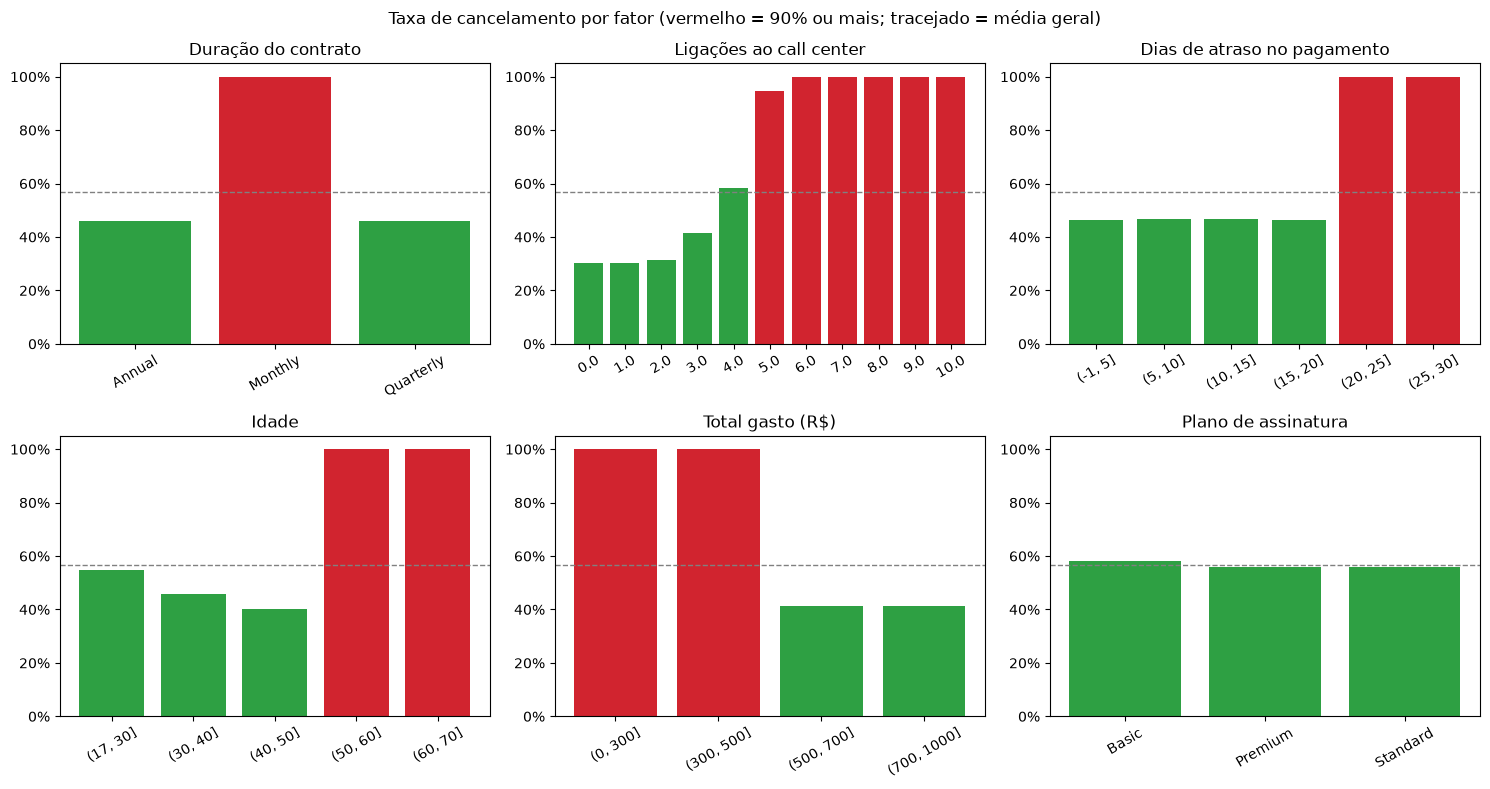

In [3]:
def taxa_por(coluna, faixas=None):
    """Taxa de cancelamento por categoria (ou por faixa, se for número contínuo)."""
    chave = pd.cut(tabela[coluna], faixas) if faixas is not None else tabela[coluna]
    return tabela.groupby(chave, observed=True)["cancelou"].mean()

fatores = {
    "Duração do contrato": taxa_por("duracao_contrato"),
    "Ligações ao call center": taxa_por("ligacoes_callcenter"),
    "Dias de atraso no pagamento": taxa_por("dias_atraso", [-1, 5, 10, 15, 20, 25, 30]),
    "Idade": taxa_por("idade", [17, 30, 40, 50, 60, 70]),
    "Total gasto (R$)": taxa_por("total_gasto", [0, 300, 500, 700, 1000]),
    "Plano de assinatura": taxa_por("assinatura"),
}

fig, eixos = plt.subplots(2, 3, figsize=(15, 8))
for eixo, (titulo, serie) in zip(eixos.flat, fatores.items()):
    cores = ["#d1242f" if v >= 0.9 else "#2ea043" for v in serie.values]
    eixo.bar(serie.index.astype(str), serie.values, color=cores)
    eixo.axhline(tabela["cancelou"].mean(), color="gray", linestyle="--", linewidth=1)
    eixo.set_title(titulo); eixo.set_ylim(0, 1.05); eixo.tick_params(axis="x", rotation=30)
    eixo.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
fig.suptitle("Taxa de cancelamento por fator (vermelho = 90% ou mais; tracejado = média geral)")
fig.tight_layout()
plt.show()

In [4]:
# Os limites exatos a partir dos quais TODO cliente cancelou
def limite_de_100(coluna, maior=True):
    taxa = tabela.groupby(coluna)["cancelou"].mean()
    valores = taxa[taxa == 1].index
    return valores.min() if maior else valores.max()

print("ligações ao call center: a partir de", limite_de_100("ligacoes_callcenter"))
print("dias de atraso: a partir de", limite_de_100("dias_atraso"))
print("idade: a partir de", limite_de_100("idade"))
print("contrato mensal:", f'{taxa_por("duracao_contrato")["Monthly"]:.0%} cancelaram')

ligações ao call center: a partir de 6.0
dias de atraso: a partir de 21.0
idade: a partir de 51.0
contrato mensal: 100% cancelaram


### O que os dados mostram

- **Contrato mensal:** 100% cancelaram. Anual e trimestral ficam em ~46%.
- **Call center:** até 2 ligações, ~30% cancelam; com 5, 95%; a partir de 6, todos.
- **Atraso:** acima de 20 dias, todos cancelaram.
- **Idade e gasto:** clientes acima de 50 anos e os que gastaram pouco também cancelaram em 100% dos casos.
- **Plano** (Basic, Standard, Premium) quase não muda a taxa: não é por aí.

## Simulação: quanto cai o cancelamento se a empresa agir nos fatores controláveis

Idade não é algo que a empresa controla. Contrato, atendimento e cobrança são.

In [5]:
regras = {
    "sem contrato mensal": tabela["duracao_contrato"] != "Monthly",
    "até 4 ligações ao call center": tabela["ligacoes_callcenter"] <= 4,
    "até 20 dias de atraso": tabela["dias_atraso"] <= 20,
}

filtro = pd.Series(True, index=tabela.index)
linhas = [("situação atual", tabela["cancelou"].mean(), len(tabela))]
for nome, condicao in regras.items():
    filtro &= condicao
    linhas.append((f"+ {nome}", tabela.loc[filtro, "cancelou"].mean(), filtro.sum()))

simulacao = pd.DataFrame(linhas, columns=["cenário", "taxa de cancelamento", "clientes"]).set_index("cenário")
simulacao.style.format({"taxa de cancelamento": "{:.1%}", "clientes": "{:,.0f}"})

,taxa de cancelamento,clientes
cenário,,
situação atual,56.7%,"881,659"
+ sem contrato mensal,46.1%,"707,454"
+ até 4 ligações ao call center,26.4%,"515,048"
+ até 20 dias de atraso,18.4%,"464,479"


## Conclusões e recomendações

1. **Acabar com o contrato mensal ou migrar esses clientes** para trimestral/anual com incentivo: hoje é cancelamento garantido.
2. **Resolver no primeiro contato:** a partir da 5ª ligação o cliente praticamente já saiu. Um alerta na 3ª ligação dá tempo de agir.
3. **Cobrança preventiva antes dos 20 dias de atraso** (lembrete, renegociação, desconto pra regularizar).

Com os três fatores controláveis tratados, a taxa de cancelamento do grupo restante cai de **56,7% para 18,4%**.

> **Ressalva:** limites tão bem definidos (100% exatos) são típicos de base didática/sintética. Numa base real eu validaria com um modelo e um teste A/B antes de recomendar a mudança.